In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


       Edad   Salario  Compra
0 -0.999102 -0.663860       1
1  1.246686  1.153597       1
2  0.962777  0.859397       1
3 -2.957441  2.033645       1
4  1.141165  1.059449       1
              Edad      Salario       Compra
count  1000.000000  1000.000000  1000.000000
mean     -0.048433    -0.022545     0.502000
std       1.322137     1.403956     0.500246
min      -3.836929    -4.543441     0.000000
25%      -1.021008    -1.054538     0.000000
50%      -0.224366    -0.197133     1.000000
75%       0.969732     0.990549     1.000000
max       3.994644     4.020262     1.000000


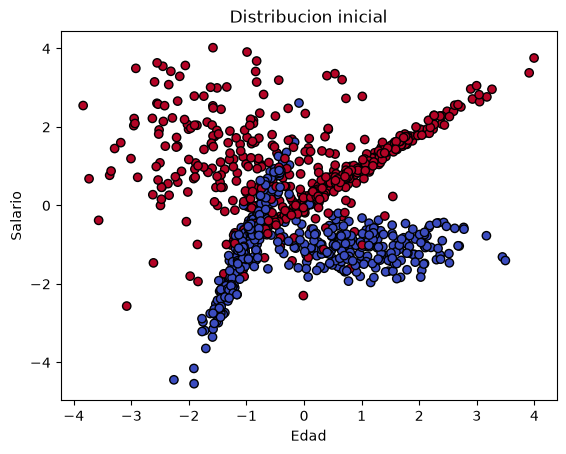

In [6]:
#Carga de datos y exploracion

import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

x, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    random_state=42
)

data = pd.DataFrame(x, columns=["Edad", "Salario"])
data["Compra"] = y

print(data.head())
print(data.describe())

plt.scatter(data["Edad"], data["Salario"], c = y, cmap="coolwarm", edgecolors="k")
plt.title("Distribucion inicial")
plt.xlabel("Edad")
plt.ylabel("Salario")
plt.show()

Procesamiento de datos

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_sclaed = scaler.fit_transform(x)

x_train, x_test, y_train, y_test = train_test_split(x_sclaed, y, test_size=0.2, random_state=42)

print(f"Tamaño del conjunto de entrenamiento: {x_train.shape[0]}")
print(f"Tamaño del conjunto de prueba: {x_test.shape[0]}")

Tamaño del conjunto de entrenamiento: 800
Tamaño del conjunto de prueba: 200


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

logreg = LogisticRegression(random_state=42)
logreg.fit(x_train, y_train)

y_pred = logreg.predict(x_test)
print("Reporte de clasificacion: ")
print(classification_report(y_test, y_pred))

accuracy = accuracy_score(y_test, y_pred)
print(f"Precision inicial: {accuracy:.2f}")

Reporte de clasificacion: 
              precision    recall  f1-score   support

           0       0.88      0.88      0.88       101
           1       0.88      0.88      0.88        99

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.88      0.88      0.88       200

Precision inicial: 0.88


In [11]:
#Ajuste de hiperparametros
from sklearn.model_selection import GridSearchCV

param_grid = {"C": [0.01, 0.1, 1, 10, 100], "solver": ["lbfgs", "liblinear"]}

grid_search = GridSearchCV(LogisticRegression(random_state=42), param_grid, cv=5, scoring="accuracy")
grid_search.fit(x_train, y_train)

best_model = grid_search.best_estimator_
print("Mejores hiperparametros: ", grid_search.best_params_)

y_pred_best = best_model.predict(x_test)
print("Reporte de clasificacion del mejor modelo: ")
print(classification_report(y_test, y_pred_best))

Mejores hiperparametros:  {'C': 0.01, 'solver': 'liblinear'}
Reporte de clasificacion del mejor modelo: 
              precision    recall  f1-score   support

           0       0.87      0.90      0.88       101
           1       0.89      0.86      0.88        99

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.88      0.88      0.88       200



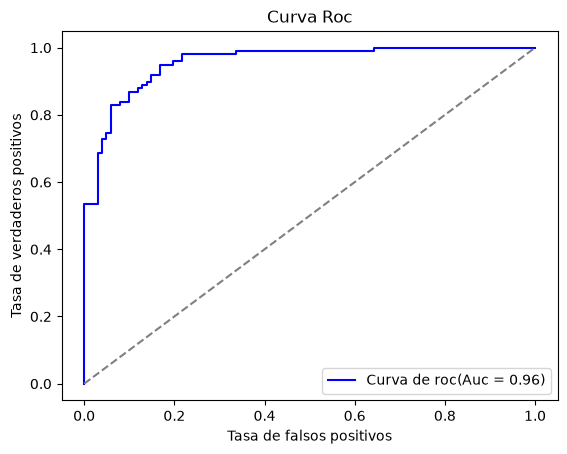

In [12]:
from sklearn.metrics import roc_curve, auc

y_prob = best_model.predict_proba(x_test)[:,1]
fpr, tpr, _= roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, color = "blue", label=f"Curva de roc(Auc = {roc_auc:.2f})")
plt.plot([0,1],[0,1], color="gray", linestyle="--")
plt.title("Curva Roc")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc = "lower right")
plt.show()